In [1]:
import os
import yaml

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import cartopy.crs as ccrs
from pathlib import Path

from reader.io_utils import load_processed_datasets
from plotting.labels import format_forecast_titles
from plotting.maps import plot_variable_panel, plot_fire_perimeters


ERROR 1: PROJ: proj_create_from_database: Open of /home/dnash/miniconda3/envs/SEAK-impacts/share/proj failed


In [2]:
  
def save_figure(
    fig,
    domain_name,
    init_date,
    out_root="output/figures",
    dpi=300,
    filetype="png",
):
    """
    Save figure to output directory.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure object to save
    domain_name : str
        Domain name (e.g. 'SEAK')
    init_date : str
        Initialization date (e.g. '2026010100')
    out_root : str, optional
        Root output directory
    dpi : int, optional
        Output resolution
    filetype : str, optional
        File extension (png, pdf, jpg)
    """

    out_dir = Path(out_root) / domain_name
    out_dir.mkdir(parents=True, exist_ok=True)

    fname = out_dir / f"mclimate_{domain_name}_{init_date}.{filetype}"

    print(f"Saving figure: {fname}")

    fig.savefig(
        fname,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white",
    )

    return fname

In [3]:
# init_date = "2021012700"
# lead_time=9

# init_date = "2021012600"
# lead_time=33

# init_date = "2021012400"
# lead_time=81

In [4]:
# ==========================================================
# User settings
# ==========================================================

init_date = "2021012700"
lead_time=6

varname = 'qpf'
domain_name = 'Central_CA'
source='archive'


domain = {
    "lon_min": -125.,
    "lon_max": -110.,
    "lat_min": 25.,
    "lat_max": 50.,
}


# ---------------------------------------------------------
# Domain config
# ---------------------------------------------------------

with open(
    "config/domain.yaml",
    "r",
) as f:

    config = yaml.safe_load(f)

domain_cfg = (
    config["domains"][domain_name]
)



In [5]:
# ---------------------------------------------------------
# Load processed datasets
# ---------------------------------------------------------

fc, final_ds = (
    load_processed_datasets(
        init_date=init_date,
        source=source,
    )
)

/home/dnash/miniconda3/envs/SEAK-impacts/lib/python3.12/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'gini' loading failed:
Struct() takes at most 1 argument (3 given)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [6]:
final_ds = final_ds.mean("number")
fc = fc.mean("number")

In [7]:
labels = format_forecast_titles(domain_cfg, init_date, lead_time)
title = labels["left"]+ " " + labels["right"]

Plotting M-Climate map for qpf


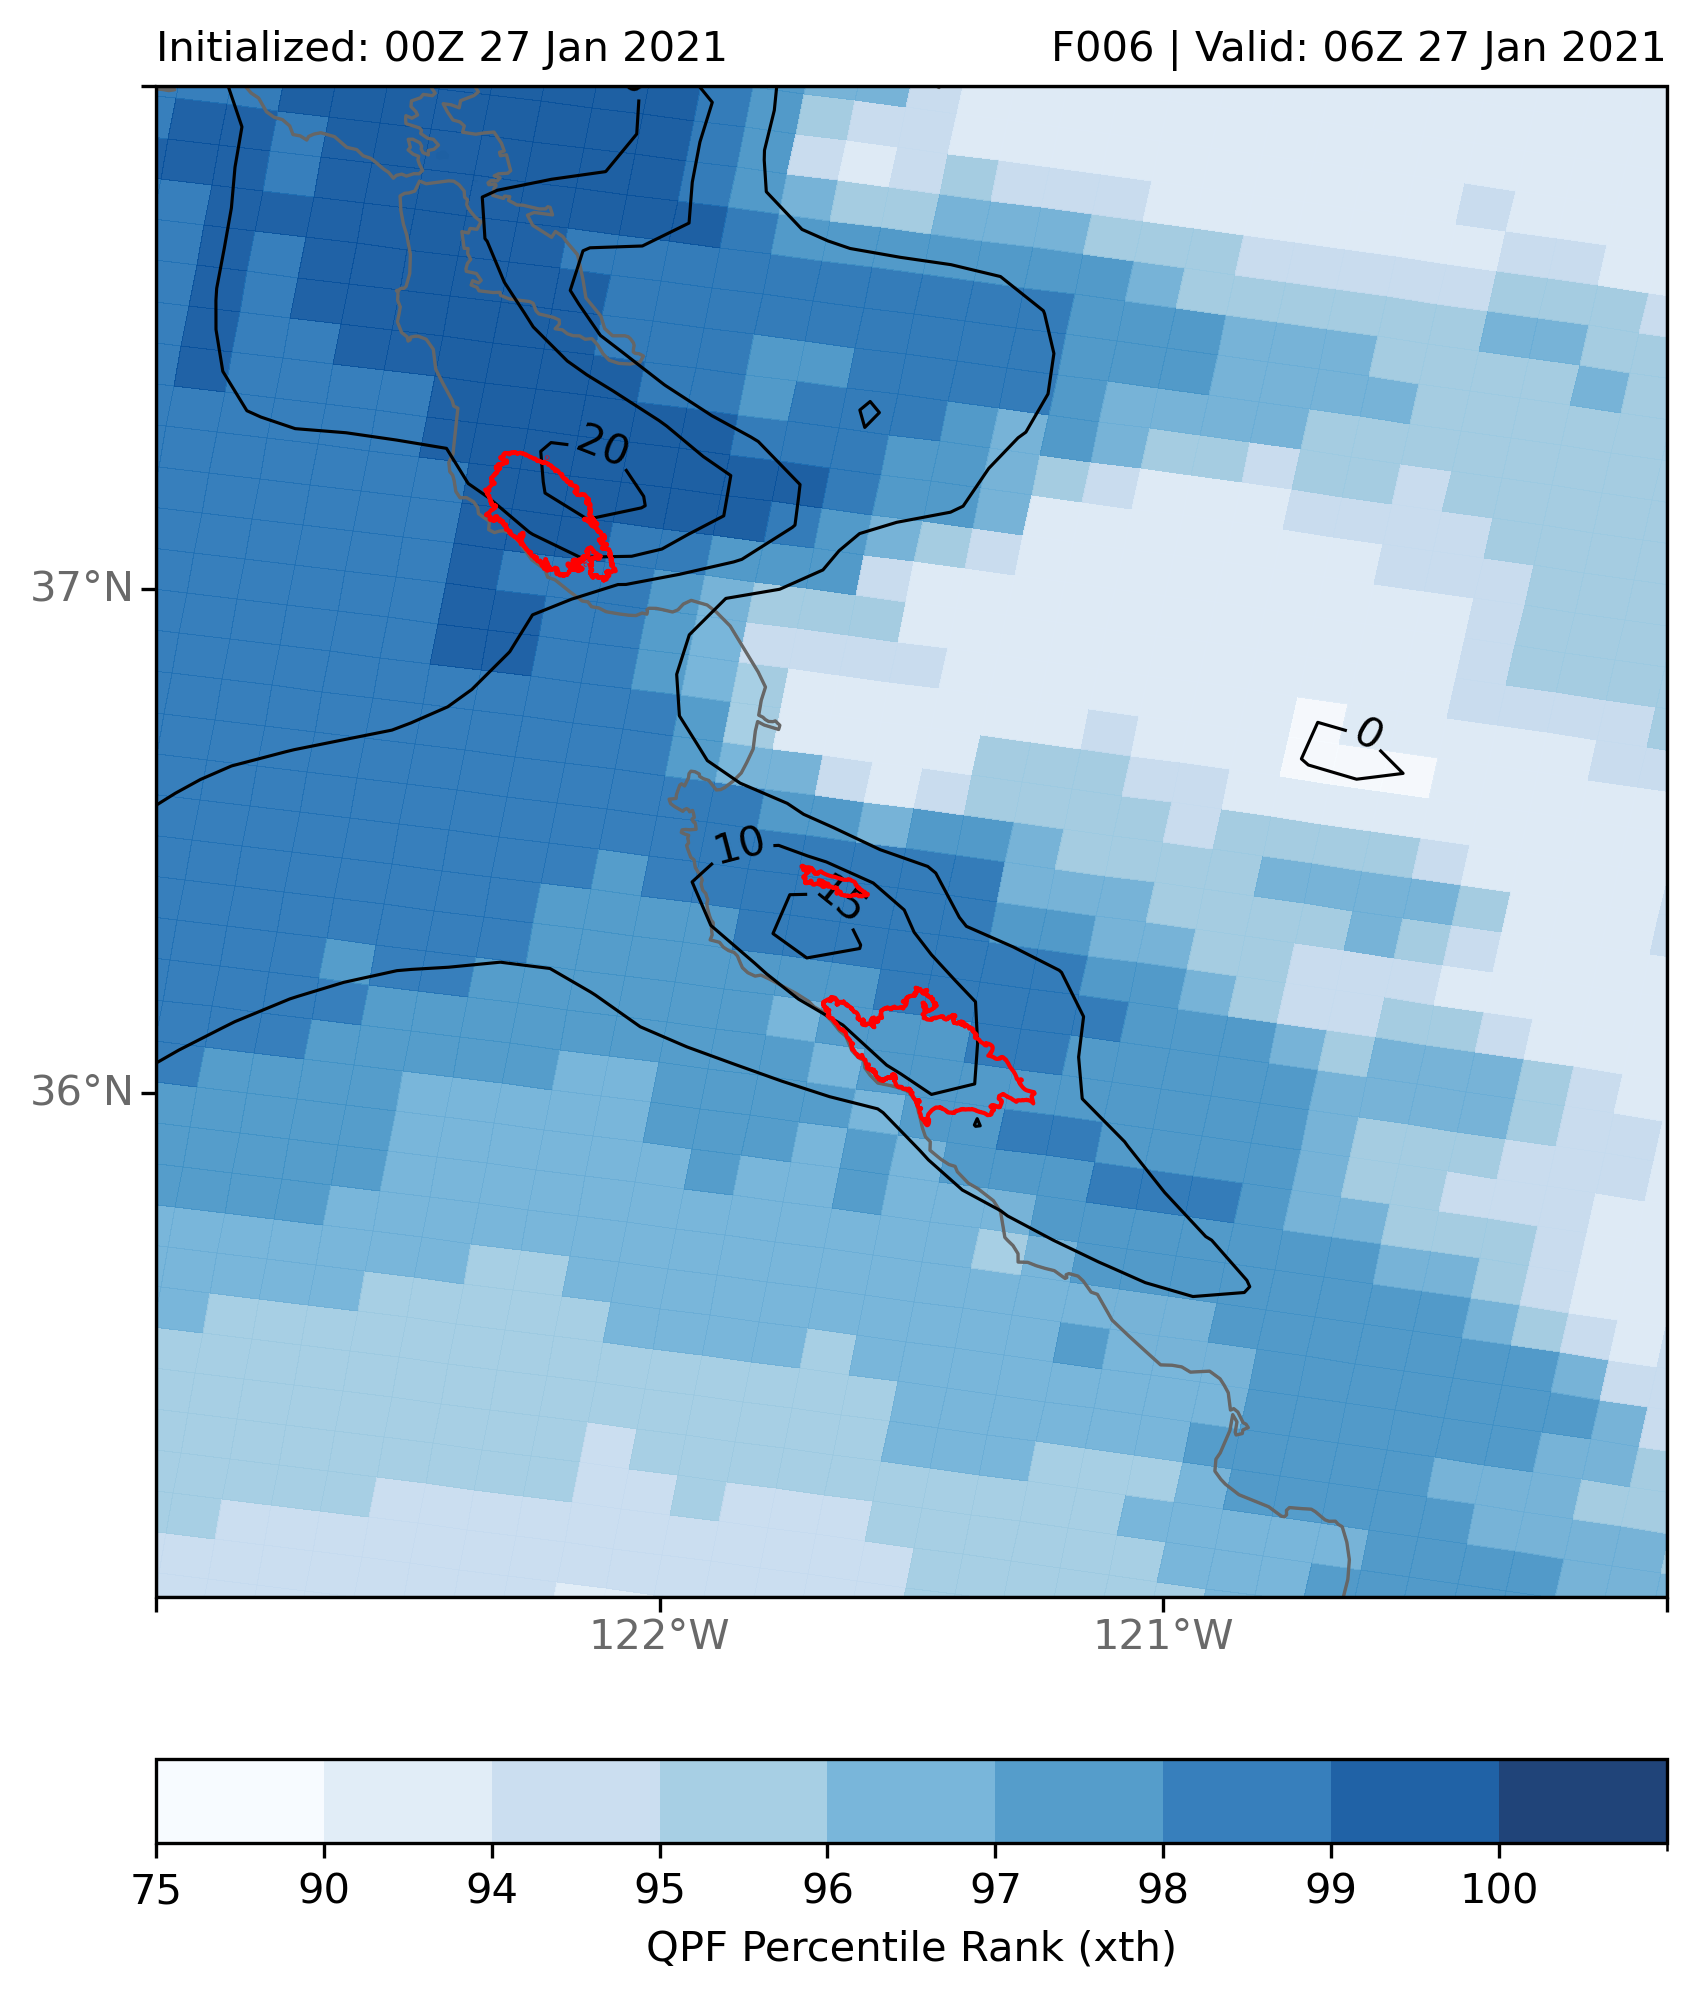

Saving figure: output/figures/Central_CA/mclimate_Central_CA_2021012700.png


PosixPath('output/figures/Central_CA/mclimate_Central_CA_2021012700.png')

In [8]:
# ---------------------------------------------------------------------
# Setup Figure
# ---------------------------------------------------------------------

current_dpi = 300

fig = plt.figure(figsize=(6.5, 8), # inches wide, high
                 dpi=current_dpi)
gs = GridSpec(
    nrows=2, ncols=1,
    width_ratios=[1],
    height_ratios=[1, 0.05],
    wspace=0.05, hspace=0.08
)

datacrs = ccrs.PlateCarree()
mapcrs = ccrs.PlateCarree()

## plot QPF map
qpf_ax = plot_variable_panel(
    fig=fig,
    gs_loc=gs[0, 0], 
    domain_cfg=domain_cfg, 
    lats_lbl=True, 
    ds=final_ds, 
    fc=fc, 
    lead_time=lead_time, 
    config_key="qpf",
    cax=gs[-1, 0],
    labels=labels)

# add fire perimeters
plot_fire_perimeters(qpf_ax)

plt.show()

save_figure(
    fig,
    domain_name,
    init_date)